In [1]:
%matplotlib inline
import os
from os.path import join as pjoin
from tifffile import imread, imwrite, TiffFile
import numpy as np
import shutil
import matplotlib.pyplot as plt
from glob import glob
import pandas as pd
import cv2
from tqdm import tqdm
import subprocess
from wf_utils import *
from wfield_utils import *
# from multi_load_images import *


In [2]:
os.environ['CUDA_VISIBLE_DEVICES'] = '3'
import cupy as cp
cp._default_memory_pool.free_all_blocks()


In [3]:
def phasemap(path_wfield, path_out, SVTcorr, mouse, nrepeats=10, post_trial=3, export_ave_tif=True, export_raw_tif=False,
             plot_snr=True, plot_phasemasp=True, export_phase=True):
    ### 路径和刺激重复次数。（本代码对应的是每个方向连续重复10次再下一个方向）
    # path_out = pjoin(path_wfield, '..', os.path.basename(path_wfield)[:16] + 'retinotopy')
    os.makedirs(path_out, exist_ok=True)
    os.makedirs(pjoin(path_out,'tif'), exist_ok=True)

    ### load data
    trials = pd.read_csv(pjoin(path_wfield, "trials.csv"), header=None, dtype=int).values
    nframes_el = min(trials[:20, 3]) + post_trial * 10
    nframes_az = min(trials[20:40, 3]) + post_trial * 10
    U = np.load(pjoin(path_wfield, 'U.npy'))
    # SVTcorr = np.load(pjoin(path_wfield, 'SVTcorr.npy'))
    nSVD = SVTcorr.shape[0]

    ### extract trial-data for 4 direction stimuli respectively.
    def _sort_frames(nframes, *ntrials):
        stack = np.empty((nSVD, nframes, 0))
        raw = np.empty((nSVD, 0))
        for i in ntrials:
            stack = np.concatenate((stack, SVTcorr[:, trials[i, 1]:trials[i, 1] + nframes].reshape(nSVD, nframes, 1)),
                                   axis=2)
            raw = np.concatenate((raw, SVTcorr[:, trials[i, 1]:trials[i, 1] + nframes]), axis=1)
        avg = np.mean(stack, axis=2)
        return avg, raw, stack

    avg_up, raw_up, stack_up = _sort_frames(nframes_el, *range(nrepeats * 0, nrepeats * 1))
    avg_down, raw_down, stack_down = _sort_frames(nframes_el, *range(nrepeats * 1, nrepeats * 2))
    avg_left, raw_left, stack_left = _sort_frames(nframes_az, *range(nrepeats * 2, nrepeats * 3))
    avg_right, raw_right, stack_right = _sort_frames(nframes_az, *range(nrepeats * 3, nrepeats * 4))

    if export_ave_tif is True:
        # export trial-average tif
        imwrite(pjoin(path_out, 'tif', 'avg_up.tif'), reconstruct(U, avg_up).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'avg_down.tif'), reconstruct(U, avg_down).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'avg_left.tif'), reconstruct(U, avg_left).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'avg_right.tif'), reconstruct(U, avg_right).astype('float32'), imagej=True)
        print('Finish exporting average tif')

    if export_raw_tif is True:
        imwrite(pjoin(path_out, 'tif', 'rep_up.tif'), reconstruct(U, raw_up).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'rep_down.tif'), reconstruct(U, raw_down).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'rep_left.tif'), reconstruct(U, raw_left).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'rep_right.tif'), reconstruct(U, raw_right).astype('float32'), imagej=True)
        print('Finish exporting rep tif')

    if plot_snr is True:
        snr_up = cal_snr(np.tensordot(U, stack_up, axes=(2, 0)), 3, 2)
        snr_down = cal_snr(np.tensordot(U, stack_down, axes=(2, 0)), 3, 2)
        snr_left = cal_snr(np.tensordot(U, stack_left, axes=(2, 0)), 3, 2)
        snr_right = cal_snr(np.tensordot(U, stack_right, axes=(2, 0)), 3, 2)

        vmin = 0
        vmax = max(snr_up.max(), snr_down.max(), snr_left.max(), snr_right.max())
        fig = plt.figure(figsize=[20, 5])

        axis_up = fig.add_subplot(1, 4, 1)
        plt.imshow(snr_up, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_up.set_title('up_snr')

        axis_down = fig.add_subplot(1, 4, 2)
        plt.imshow(snr_down, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_down.set_title('down_snr')

        axis_left = fig.add_subplot(1, 4, 3)
        plt.imshow(snr_left, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_left.set_title('left_snr')

        axis_right = fig.add_subplot(1, 4, 4)
        plt.imshow(snr_right, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_right.set_title('right_snr')

        plt.suptitle(f'{mouse} {os.path.basename(path_wfield)[:15]} retinotopy_snr')
        fig.set_facecolor('white')
        plt.savefig(pjoin(path_out, f'{mouse}_{os.path.basename(path_wfield)[:15]}_retinotopy_snr.png'), bbox_inches='tight')
        plt.show()

    if plot_phasemasp is True:
        ### computes fft in SVD space
        from scipy.ndimage import gaussian_filter,median_filter
        # mov = runpar(median_filter, U.transpose((2, 0, 1)), size=1)
        # U = np.stack(mov).transpose((1, 2, 0)).astype(np.float32)
        up = reconstruct(U, fft(raw_up.T, axis=0)[nrepeats])
        down = reconstruct(U, fft(raw_down.T, axis=0)[nrepeats])
        left = reconstruct(U, fft(raw_left.T, axis=0)[nrepeats])
        right = reconstruct(U, fft(raw_right.T, axis=0)[nrepeats])
        # phase_el = -1. * (np.angle(up) - np.angle(down)) % (2 * np.pi)
        # phase_az = -1. * (np.angle(left) - np.angle(right)) % (2 * np.pi)
        phase_el = (np.angle(up) % (2*np.pi)) - (np.angle(down)) % (2*np.pi)
        phase_az = (np.angle(left) % (2*np.pi)) - (np.angle(right)) % (2*np.pi)
        mag_el = (np.abs(up + down) * 2.)
        mag_az = (np.abs(left + right) * 2.)


        ################## plot summary map ###################
        phase_az_filt = gaussian_filter(phase_az,0.5)
        phase_el_filt = gaussian_filter(phase_el,0.5)
        mag_el_filt = median_filter(mag_el,3)
        mag_az_filt = median_filter(mag_az,3)
        signmap = visual_sign_map(phase_el_filt, phase_az_filt)
        signmap_filt = gaussian_filter(signmap,10)


        fig = plt.figure(figsize=[15, 10])
        fig.add_subplot(3, 4, 1)
        plt.imshow(cp.asnumpy(np.angle(up)),cmap='tab20')
        plt.title('up')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 2)
        plt.imshow(cp.asnumpy(np.angle(down)),cmap='tab20')
        plt.title('down')
        plt.colorbar()
        plt.axis('off')
        fig.add_subplot(3, 4, 3)
        plt.imshow(phase_el,cmap='tab20')
        plt.title('phase_elevation')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 4)
        plt.imshow(phase_el_filt,cmap='hsv', interpolation='nearest')
        plt.title('phase_elevation filter')
        plt.axis('off')
        plt.colorbar()

        fig.add_subplot(3, 4, 5)
        plt.imshow(cp.asnumpy(np.angle(left)),cmap='tab20')
        plt.title('left')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 6)
        plt.imshow(cp.asnumpy(np.angle(right)),cmap='tab20')
        plt.title('right')
        plt.colorbar()
        plt.axis('off')
        fig.add_subplot(3, 4, 7)
        plt.imshow(phase_az,cmap='tab20')
        plt.title('phase_azimuth')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 8)
        plt.imshow(phase_az_filt,cmap='hsv', interpolation='nearest')
        plt.title('phase_azimuth filter')
        plt.axis('off')
        plt.colorbar()

        fig.add_subplot(3, 4, 9)
        plt.imshow(mag_el_filt, cmap='hot', interpolation='nearest')
        plt.title('power_elevation')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 10)
        plt.imshow(mag_az_filt, cmap='hot', interpolation='nearest')
        plt.title('power_azimuth')
        plt.axis('off')
        plt.colorbar()


        fig.add_subplot(3, 4, 11)
        plt.imshow(signmap, vmin=-1, vmax=1, cmap='RdBu_r', interpolation='nearest')
        plt.title('signmap')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 12)
        plt.imshow(signmap_filt, vmin=-1, vmax=1, cmap='RdBu_r', interpolation='nearest')
        plt.title('signmap filter')
        plt.axis('off')
        plt.colorbar()

        fig.set_facecolor('white')
        plt.suptitle(f'{mouse} {os.path.basename(path_wfield)[:15]} summary', fontsize=18)
        plt.savefig(pjoin(path_out, f'{mouse}_{os.path.basename(path_wfield)[:15]}_summary_map.png'), bbox_inches='tight')
        plt.show()
        #################################

        fig = plt.figure(figsize=[15, 5])
        # plot phase maps
        axis_az = fig.add_subplot(1, 3, 1)
        plt.imshow(im_fftphase_hsv([mag_az, phase_az]))
        plt.axis('off')
        axis_az.set_title('azimuth phase')
        axis_el = fig.add_subplot(1, 3, 2)
        plt.imshow(im_fftphase_hsv([mag_el, phase_el]))
        plt.axis('off')
        axis_el.set_title('elevation phase')
        # plot sign maps
        axis_az = fig.add_subplot(1, 3, 3)
        plt.imshow(median_filter(visual_sign_map(phase_az, phase_el), 20), cmap='RdBu_r', clim=[-1, 1])
        plt.colorbar(shrink=0.5)
        plt.axis('off')
        axis_az.set_title('signmap')
        # plt.annotate('window: stim_length + {} s'.format(post_trial), xy=(0, 1), xycoords='axes fraction',
        #                 fontsize=12, rotation=0, va='center')
        plt.suptitle(f'{mouse} {os.path.basename(path_wfield)[:15]}')
        fig.set_facecolor('white')
        plt.savefig(pjoin(path_out, f'{mouse}_{os.path.basename(path_wfield)[:15]}_phasemap+signmap.png'), bbox_inches='tight')
        plt.show()


        if export_phase is True:
            ### export phase and magnitude
            np.save(pjoin(path_out, 'phase_el.npy'), phase_el)
            np.save(pjoin(path_out, 'phase_az.npy'), phase_az)
            np.save(pjoin(path_out, 'mag_el.npy'), mag_el)
            np.save(pjoin(path_out, 'mag_az.npy'), mag_az)

        

In [4]:
# path_wfield_all=glob(pjoin('/home/lzx/data/WF_VC_liuzhaoxi/*/retinotopy/process/*-wfield'))+glob(pjoin('/home/lzx/data/WF_VC_liuzhaoxi/*/checkerboard-bar/process/*-wfield'))
path_wfield_all=glob(pjoin('/home/lzx/data/WF_VC_liuzhaoxi/*/retinotopy-*/process/*-wfield'))
path_wfield_all

['/home/lzx/data/WF_VC_liuzhaoxi/25.07.04_A6/retinotopy-1eye/process/20250704-192813-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.07.07_A11/retinotopy-1eye/process/20250707-204128-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.07.09_H70/retinotopy-1eye/process/20250709-193928-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.07.09_A9/retinotopy-1eye/process/20250709-230120-wfield']

In [ ]:
path_wfield_all = path_wfield_all[-14:-1]
path_wfield_all

In [ ]:
path_out_all=glob(pjoin('/home/lzx/data/WF_VC_liuzhaoxi/*/retinotopy/process/*retinotopy(svt470-svt405)/'))+glob(pjoin('/home/lzx/data/WF_VC_liuzhaoxi/*/checkerboard-bar/process/*retinotopy(svt470-svt405)'))
path_out_all

20250704-192813 A6


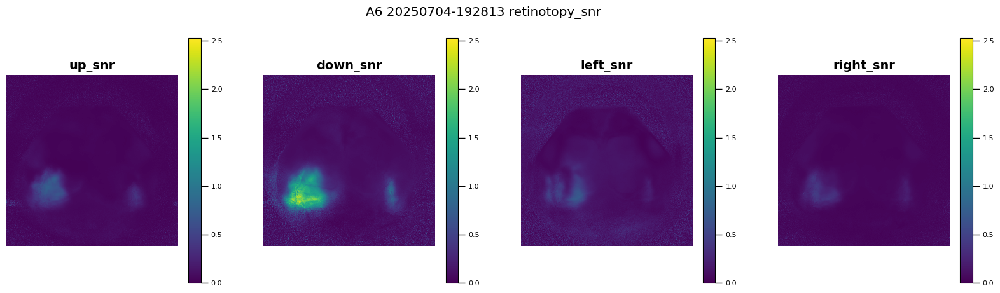

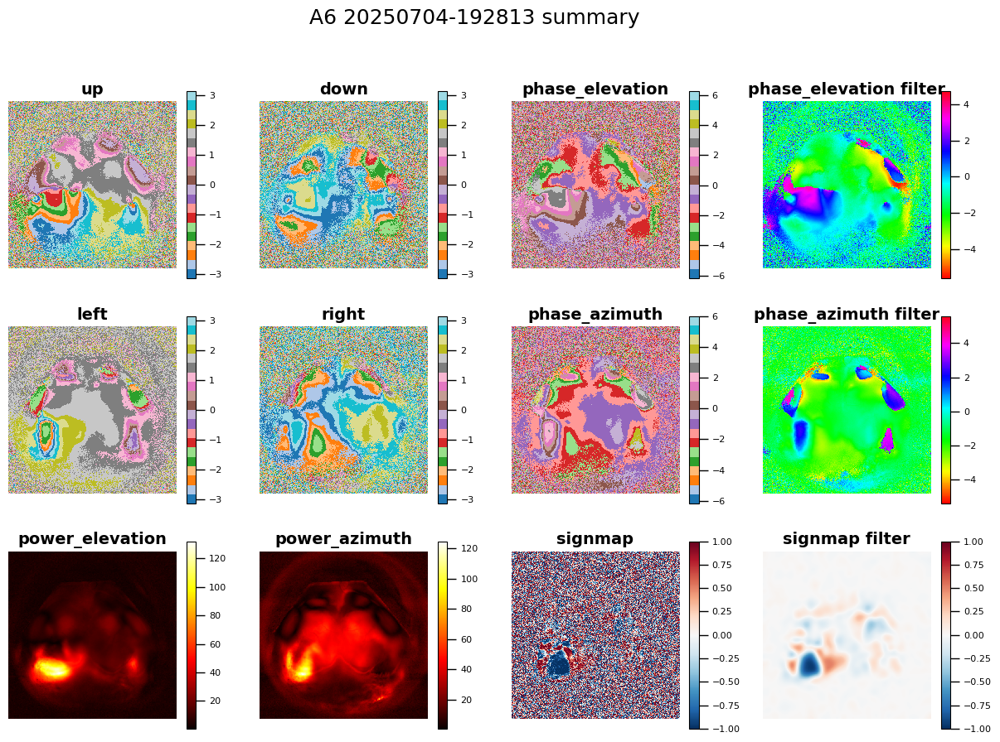

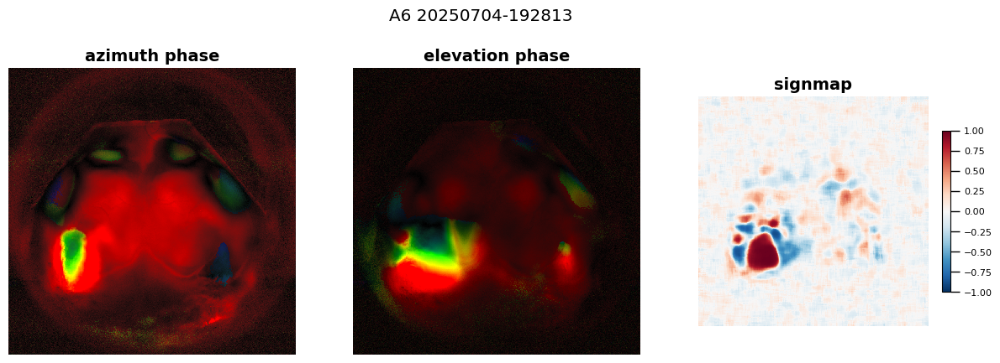

20250707-204128 A11


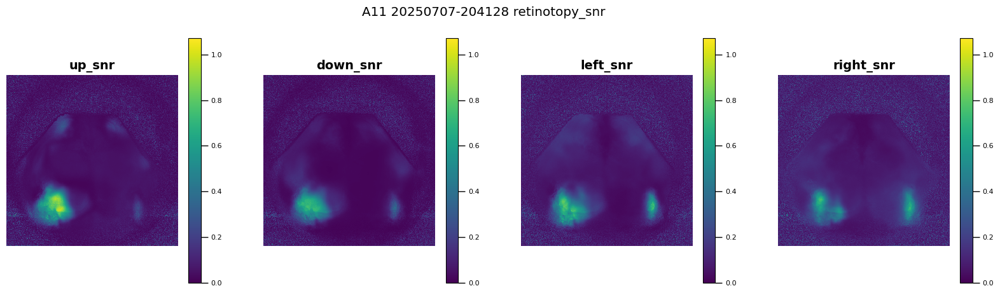

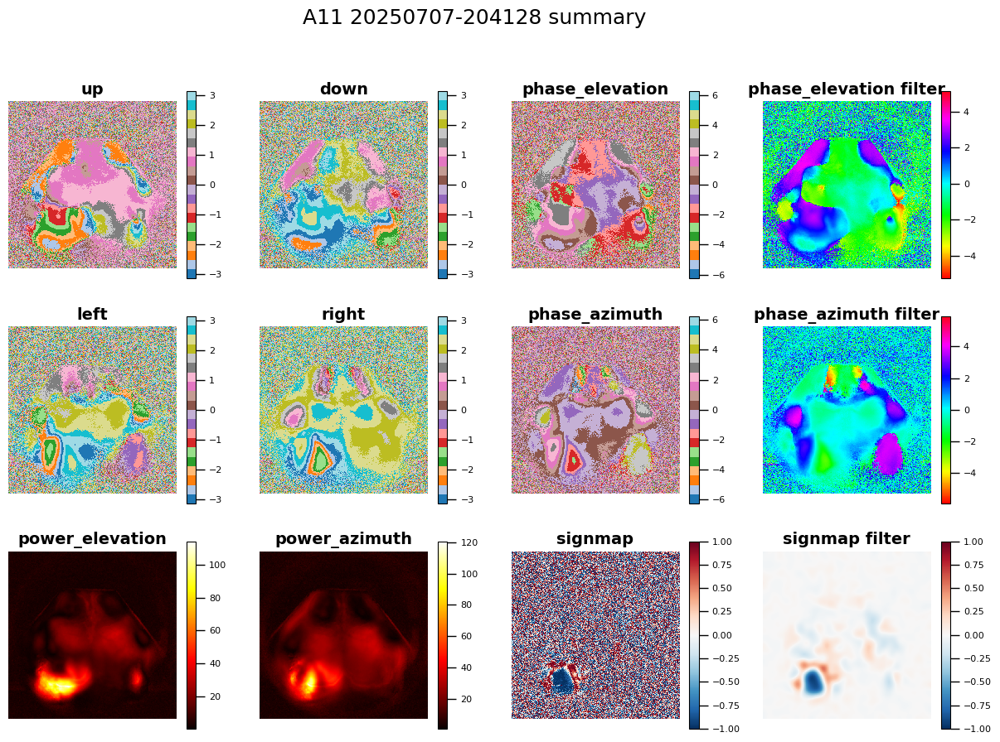

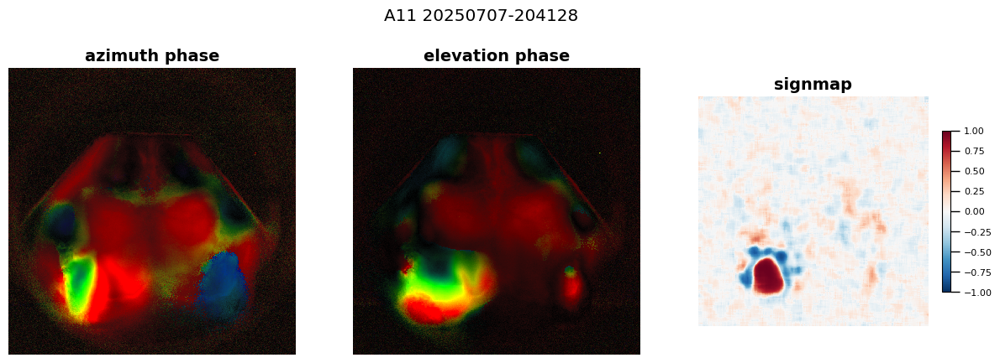

20250709-193928 H70


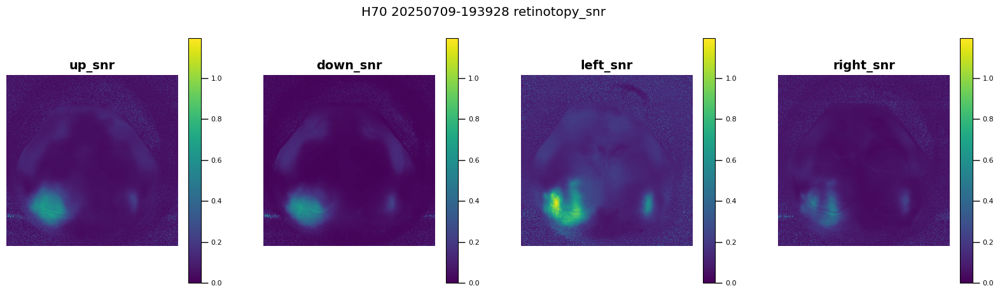

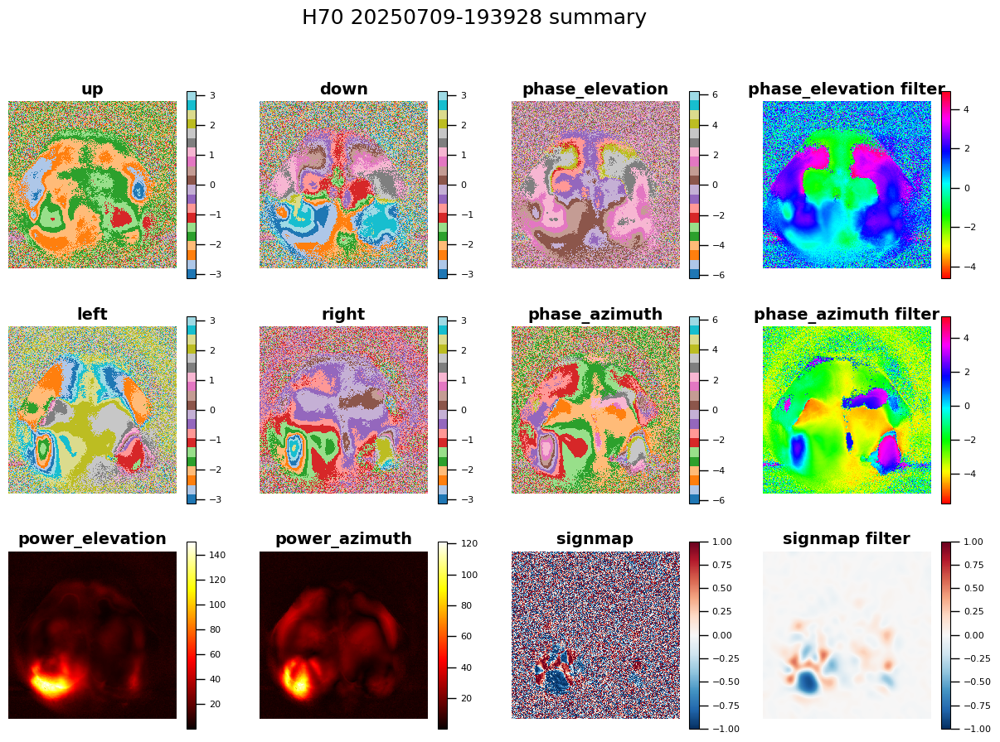

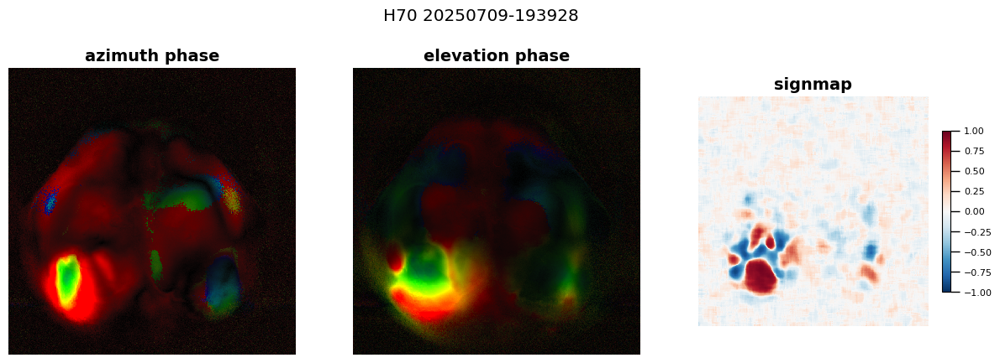

20250709-230120 A9


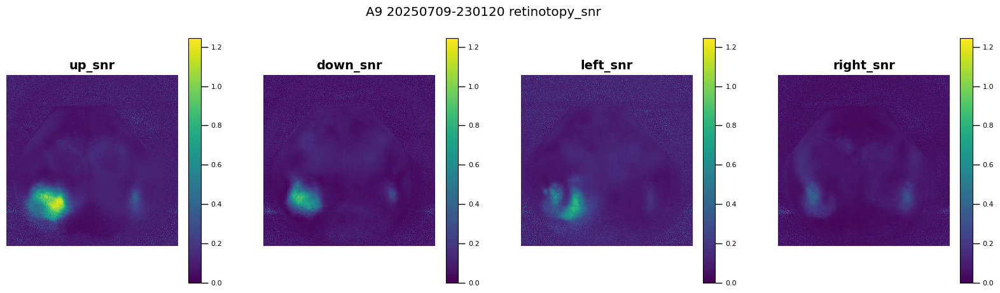

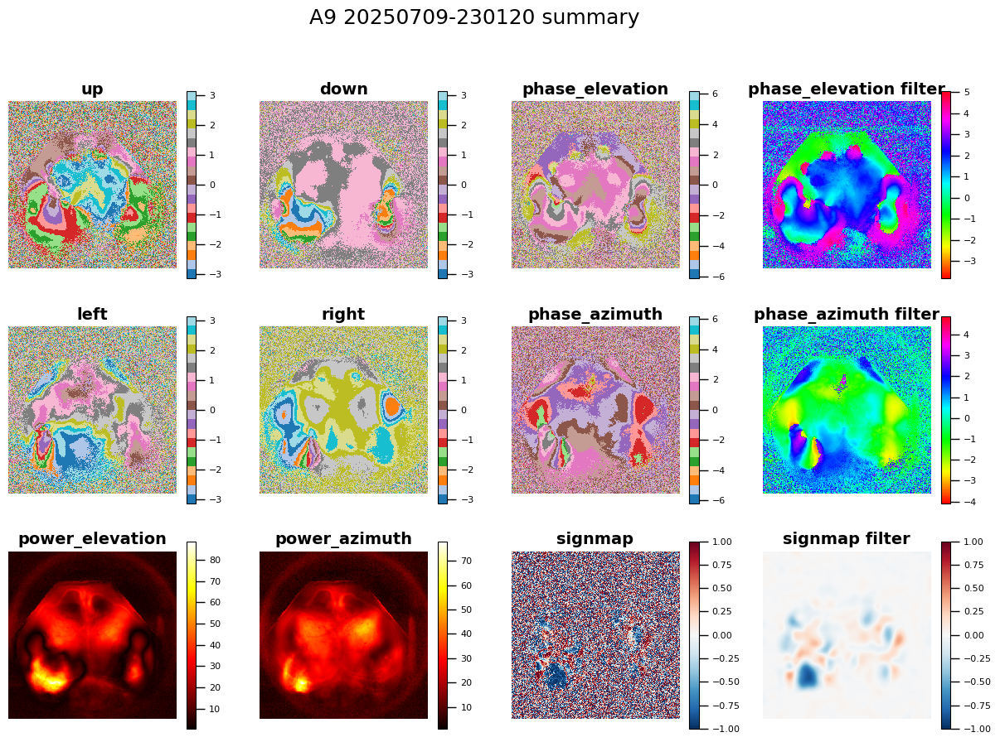

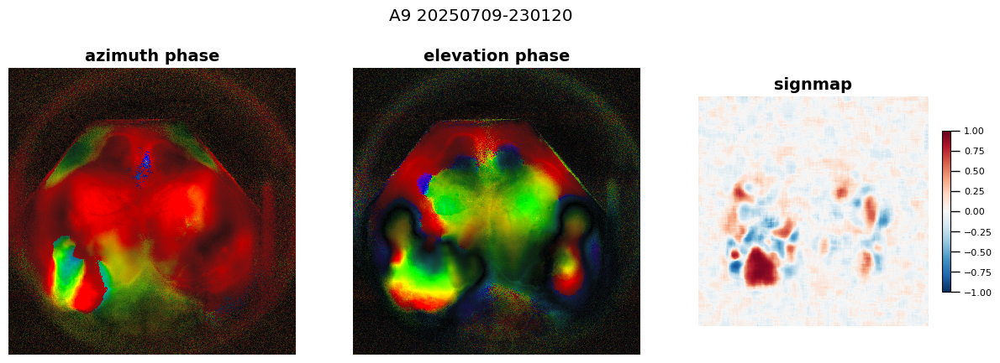

In [5]:
for path_wfield in path_wfield_all:
    experiment = os.path.basename(path_wfield)[:15]
    mouse = os.path.normpath(path_wfield).split(os.sep)[5].split('_')[1]
    print(experiment, mouse)
    rawPath = pjoin(path_wfield, '..\\..\\raw')
    path_out = pjoin(path_wfield, '..', os.path.basename(path_wfield)[:16] + 'retinotopy(svt470-svt405)')
    os.makedirs(path_out, exist_ok=True)
    
    U = np.load(pjoin(path_wfield, 'U.npy')).astype('float32')
    SVT = np.load(pjoin(path_wfield, 'SVT.npy')).astype('float32')
    SVT_470 = SVT[:,::2]
    SVT_405 = SVT[:,1::2]
    SVTcorr = SVT_470-SVT_405

    phasemap(path_wfield, path_out, SVTcorr, mouse, nrepeats=10, post_trial=3, export_ave_tif=False, export_raw_tif=False, 
    plot_snr=True, plot_phasemasp=True, export_phase=True)
    # phasemap(path_wfield, path_out, SVTcorr, mouse, nrepeats=10, post_trial=0, export_ave_tif=True, export_raw_tif=True, 
    # plot_snr=False, plot_phasemasp=False, export_phase=False)

In [ ]:
path_wfield = '/home/lzx/data/WF_VC_liuzhaoxi/24.01.22_C83/retinotopy/process/20240122-200928-wfield'

experiment = os.path.basename(path_wfield)[:15]
rawPath = pjoin(path_wfield, '..\\..\\raw')
path_out = pjoin(path_wfield, '..', experiment + '-retinotopy')
os.makedirs(path_out, exist_ok=True)

In [ ]:
U = np.load(pjoin(path_wfield, 'U.npy')).astype('float32')
SVT = np.load(pjoin(path_wfield, 'SVT.npy')).astype('float32')
SVTcorr1 = np.load(pjoin(path_wfield, 'SVTcorr.npy')).astype('float32')

SVT_470 = SVT[:,::2]
SVT_405 = SVT[:,1::2]
SVTcorr2 = SVT_470-SVT_405


In [ ]:
tif = imread(pjoin(path_wfield, experiment+'-merged.tif'))
frames_average = np.load(pjoin(path_wfield, 'frames_average.npy')).astype('float32')

tif470 = (tif[:,0]-frames_average[0])/frames_average[0]
tif405 = (tif[:,1]-frames_average[1])/frames_average[1]

tifcorr3=tif470-tif405


In [ ]:
path_wfield = '/home/lzx/data/WF_VC_liuzhaoxi/24.01.22_C83/retinotopy/process/20240122-200928-wfield'

experiment = os.path.basename(path_wfield)[:15]
rawPath = pjoin(path_wfield, '..\\..\\raw')
path_out = pjoin(path_wfield, '..', experiment + '-retinotopy')
os.makedirs(path_out, exist_ok=True)

In [ ]:
U = np.load(pjoin(path_wfield, 'U.npy')).astype('float32')
SVT = np.load(pjoin(path_wfield, 'SVT.npy')).astype('float32')
SVTcorr1 = np.load(pjoin(path_wfield, 'SVTcorr.npy')).astype('float32')

SVT_470 = SVT[:,::2]
SVT_405 = SVT[:,1::2]
SVTcorr2 = SVT_470-SVT_405


In [ ]:
tif = imread(pjoin(path_wfield, experiment+'-merged.tif'))
frames_average = np.load(pjoin(path_wfield, 'frames_average.npy')).astype('float32')

tif470 = (tif[:,0]-frames_average[0])/frames_average[0]
tif405 = (tif[:,1]-frames_average[1])/frames_average[1]

tifcorr3=tif470-tif405


Finish exporting average tif


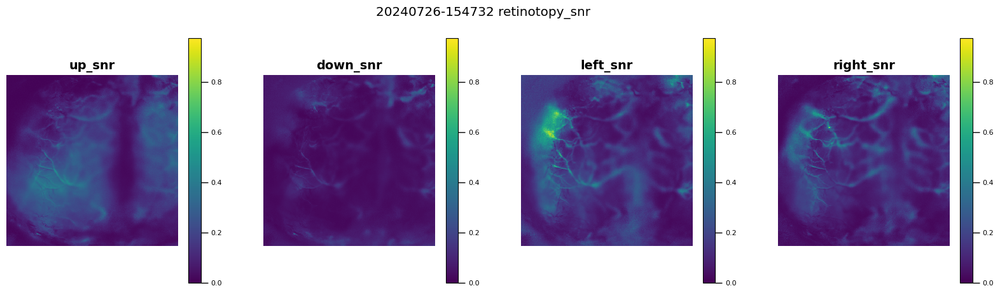

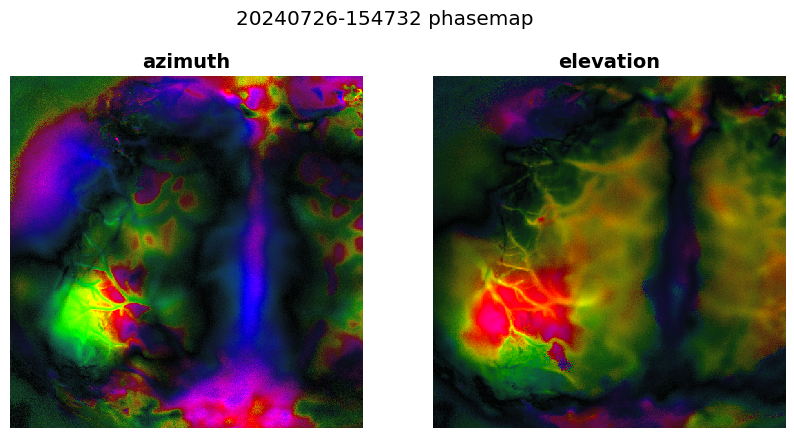

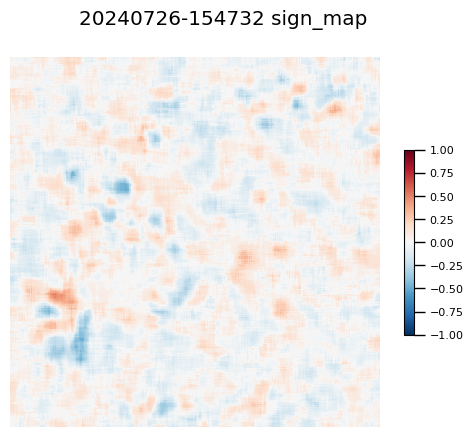

In [41]:
phasemap(path_wfield, pjoin(path_out, 'test-svd-hemo'), SVTcorr1, nrepeats=10, post_trial=3, export_ave_tif=True, export_raw_tif=False,
             plot_snr=True, plot_phasemasp=True, export_phase=False)

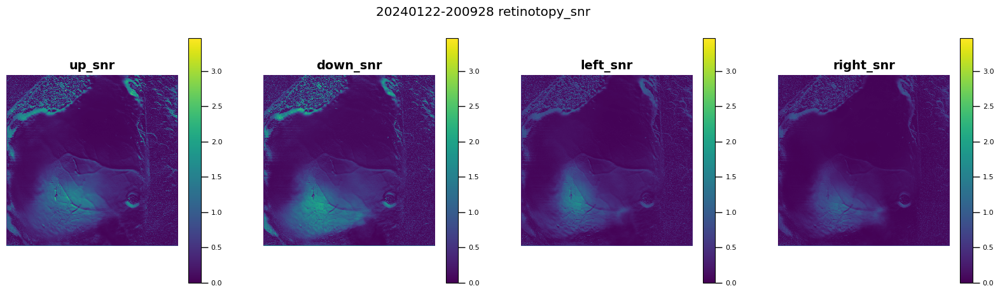

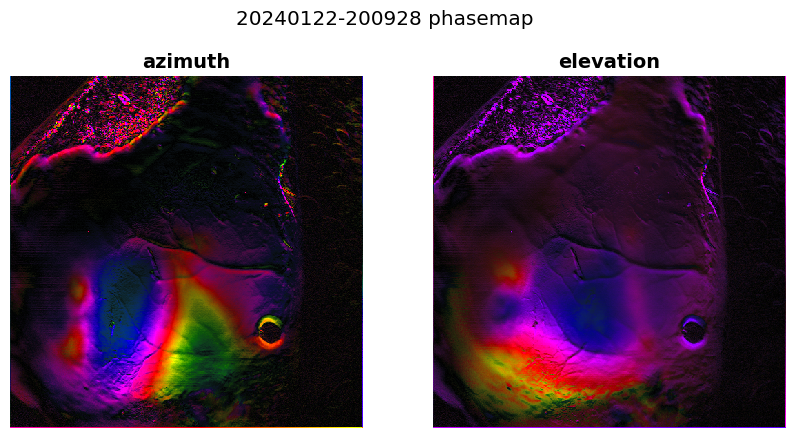

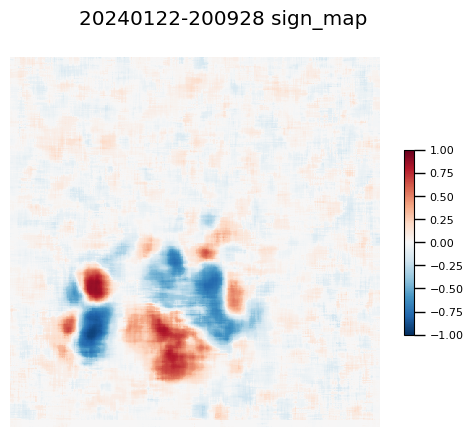

In [16]:
phasemap(path_wfield, pjoin(path_out, 'test-svd'), SVTcorr2, nrepeats=10, post_trial=3, export_ave_tif=False, export_raw_tif=False,
             plot_snr=True, plot_phasemasp=True, export_phase=False)

In [6]:
def phasemap_tif(path_wfield, path_out, tifcorr, nrepeats=10, post_trial=3, export_ave_tif=True, export_raw_tif=False,
             plot_snr=True, plot_phasemasp=True, export_phase=True):
    ### 路径和刺激重复次数。（本代码对应的是每个方向连续重复10次再下一个方向）
    path_wfield = path_wfield
    nrepeats = nrepeats
    post_trial = post_trial  # 刺激消失后多取几秒
    # path_out = pjoin(path_wfield, '..', os.path.basename(path_wfield)[:16] + 'retinotopy')
    os.makedirs(path_out, exist_ok=True)
    os.makedirs(pjoin(path_out,'tif'), exist_ok=True)

    ### load data
    trials = pd.read_csv(pjoin(path_wfield, "trials.csv"), header=None, dtype=int).values
    nframes_el = min(trials[:20, 3]) + post_trial * 10
    nframes_az = min(trials[20:40, 3]) + post_trial * 10
    # U = np.load(pjoin(path_wfield, 'U.npy'))
    # SVTcorr = np.load(pjoin(path_wfield, 'SVTcorr.npy'))
    # nSVD = SVTcorr.shape[0]
    tifcorr = cp.asarray(tifcorr)
    shape = tifcorr.shape

    ### extract trial-data for 4 direction stimuli respectively.
    def _sort_frames(nframes, *ntrials):
        stack = cp.empty((nframes, 0, *shape[1:]))
        raw = cp.empty((0, *shape[1:]))
        for i in ntrials:
            stack = cp.concatenate((stack, tifcorr[trials[i, 1]:trials[i, 1] + nframes].reshape(nframes, 1, *shape[1:])),
                                   axis=1)
            raw = cp.concatenate((raw, tifcorr[trials[i, 1]:trials[i, 1] + nframes]), axis=0)
        avg = cp.mean(stack, axis=1)
        return avg, raw, stack

    avg_up, raw_up, stack_up = _sort_frames(nframes_el, *range(nrepeats * 0, nrepeats * 1))
    avg_down, raw_down, stack_down = _sort_frames(nframes_el, *range(nrepeats * 1, nrepeats * 2))
    avg_left, raw_left, stack_left = _sort_frames(nframes_az, *range(nrepeats * 2, nrepeats * 3))
    avg_right, raw_right, stack_right = _sort_frames(nframes_az, *range(nrepeats * 3, nrepeats * 4))

    if export_ave_tif is True:
        # export trial-average tif
        imwrite(pjoin(path_out, 'tif', 'avg_up.tif'), cp.asnumpy(avg_up).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'avg_down.tif'), cp.asnumpy(avg_down).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'avg_left.tif'), cp.asnumpy(avg_left).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'avg_right.tif'), cp.asnumpy(avg_right).astype('float32'), imagej=True)
        print('Finish exporting average tif')
    del avg_up, avg_down, avg_left, avg_right
    cp._default_memory_pool.free_all_blocks()
    
    if export_raw_tif is True:
        imwrite(pjoin(path_out, 'tif', 'rep_up.tif'), cp.asnumpy(raw_up).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'rep_down.tif'), cp.asnumpy(raw_down).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'rep_left.tif'), cp.asnumpy(raw_left).astype('float32'), imagej=True)
        imwrite(pjoin(path_out, 'tif', 'rep_right.tif'), cp.asnumpy(raw_right).astype('float32'), imagej=True)
        print('Finish exporting rep tif')

    if plot_snr is True:
        snr_up = cp.asnumpy(cal_snr(stack_up, 1, 0))
        snr_down = cp.asnumpy(cal_snr(stack_down, 1, 0))
        snr_left = cp.asnumpy(cal_snr(stack_left, 1, 0))
        snr_right = cp.asnumpy(cal_snr(stack_right, 1, 0))

        vmin = 0
        vmax = max(snr_up.max(), snr_down.max(), snr_left.max(), snr_right.max())
        fig = plt.figure(figsize=[20, 5])

        axis_up = fig.add_subplot(1, 4, 1)
        plt.imshow(snr_up, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_up.set_title('up_snr')

        axis_down = fig.add_subplot(1, 4, 2)
        plt.imshow(snr_down, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_down.set_title('down_snr')

        axis_left = fig.add_subplot(1, 4, 3)
        plt.imshow(snr_left, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_left.set_title('left_snr')

        axis_right = fig.add_subplot(1, 4, 4)
        plt.imshow(snr_right, vmin=vmin, vmax=vmax)
        plt.axis('off')
        plt.colorbar()
        axis_right.set_title('right_snr')

        plt.suptitle(os.path.basename(path_wfield)[:15]+' retinotopy_snr')
        fig.set_facecolor('white')
        plt.savefig(pjoin(path_out, 'retinotopy_snr.png'), bbox_inches='tight')
        plt.show()
    del stack_up, stack_down, stack_left, stack_right
    cp._default_memory_pool.free_all_blocks()
    
    if plot_phasemasp is True:
        ### computes fft in SVD space
        from scipy.ndimage import gaussian_filter,median_filter
        up = fft(raw_up, axis=0)[nrepeats]
        down = fft(raw_down, axis=0)[nrepeats]
        left = fft(raw_left, axis=0)[nrepeats]
        right = fft(raw_right, axis=0)[nrepeats]
        # phase_el = cp.asnumpy(-1. * (np.angle(up) - np.angle(down)) % (2 * np.pi))
        # phase_az = cp.asnumpy(-1. * (np.angle(left) - np.angle(right)) % (2 * np.pi))
        phase_el = cp.asnumpy((np.angle(up) % (2*np.pi)) - (np.angle(down)) % (2*np.pi))
        phase_az = cp.asnumpy((np.angle(left) % (2*np.pi)) - (np.angle(right)) % (2*np.pi))
        mag_el = cp.asnumpy(np.abs(up + down) * 2.)
        mag_az = cp.asnumpy(np.abs(left + right) * 2.)

        ################## plot summary map ###################
        phase_az_filt = gaussian_filter(phase_az,0.5)
        phase_el_filt = gaussian_filter(phase_el,0.5)
        mag_el_filt = median_filter(mag_el,3)
        mag_az_filt = median_filter(mag_az,3)
        signmap = visual_sign_map(phase_el_filt, phase_az_filt)
        signmap_filt = gaussian_filter(signmap,10)


        fig = plt.figure(figsize=[15, 10])
        fig.add_subplot(3, 4, 1)
        plt.imshow(cp.asnumpy(np.angle(up)),cmap='tab20')
        plt.title('up')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 2)
        plt.imshow(cp.asnumpy(np.angle(down)),cmap='tab20')
        plt.title('down')
        plt.colorbar()
        plt.axis('off')
        fig.add_subplot(3, 4, 3)
        plt.imshow(phase_el,cmap='tab20')
        plt.title('phase_elevation')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 4)
        plt.imshow(phase_el_filt,cmap='hsv', interpolation='nearest')
        plt.title('phase_elevation filter')
        plt.axis('off')
        plt.colorbar()

        fig.add_subplot(3, 4, 5)
        plt.imshow(cp.asnumpy(np.angle(left)),cmap='tab20')
        plt.title('left')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 6)
        plt.imshow(cp.asnumpy(np.angle(right)),cmap='tab20')
        plt.title('right')
        plt.colorbar()
        plt.axis('off')
        fig.add_subplot(3, 4, 7)
        plt.imshow(phase_az,cmap='tab20')
        plt.title('phase_azimuth')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 8)
        plt.imshow(phase_az_filt,cmap='hsv', interpolation='nearest')
        plt.title('phase_azimuth filter')
        plt.axis('off')
        plt.colorbar()

        fig.add_subplot(3, 4, 9)
        plt.imshow(mag_el_filt, cmap='hot', interpolation='nearest')
        plt.title('power_elevation')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 10)
        plt.imshow(mag_az_filt, cmap='hot', interpolation='nearest')
        plt.title('power_azimuth')
        plt.axis('off')
        plt.colorbar()


        fig.add_subplot(3, 4, 11)
        plt.imshow(signmap, vmin=-1, vmax=1, cmap='RdBu_r', interpolation='nearest')
        plt.title('signmap')
        plt.axis('off')
        plt.colorbar()
        fig.add_subplot(3, 4, 12)
        plt.imshow(signmap_filt, vmin=-1, vmax=1, cmap='RdBu_r', interpolation='nearest')
        plt.title('signmap filter')
        plt.axis('off')
        plt.colorbar()

        fig.set_facecolor('white')
        plt.suptitle(os.path.basename(path_wfield)[:15] + ' phasemap', fontsize=18)
        plt.savefig(pjoin(path_out, 'summary_map.png'), bbox_inches='tight')
        plt.show()
        #################################

        
        fig = plt.figure(figsize=[10, 5])
        axis_az = fig.add_subplot(1, 2, 1)
        plt.imshow(im_fftphase_hsv([mag_az, phase_az]))
        plt.axis('off')
        axis_az.set_title('azimuth')
        axis_el = fig.add_subplot(1, 2, 2)
        plt.imshow(im_fftphase_hsv([mag_el, phase_el]))
        plt.axis('off')
        axis_el.set_title('elevation')
        plt.suptitle(os.path.basename(path_wfield)[:15] + ' phasemap')
        fig.set_facecolor('white')
        plt.savefig(pjoin(path_out, 'phasemap_unfiltered.png'), bbox_inches='tight')
        plt.show()

        if export_phase is True:
            ### export phase and magnitude
            np.save(pjoin(path_out, 'phase_el.npy'), phase_el)
            np.save(pjoin(path_out, 'phase_az.npy'), phase_az)
            np.save(pjoin(path_out, 'mag_el.npy'), mag_el)
            np.save(pjoin(path_out, 'mag_az.npy'), mag_az)

        ### plot sign maps
        fig = plt.figure()
        plt.imshow(median_filter(visual_sign_map(phase_az, phase_el), 20),
                   cmap='RdBu_r', clim=[-1, 1])
        plt.colorbar(shrink=0.5)
        plt.axis('off')
        plt.suptitle(os.path.basename(path_wfield)[:15] +' sign_map')
        fig.set_facecolor('white')
        # plt.annotate('window: stim_length + {} s'.format(post_trial), xy=(0, 1), xycoords='axes fraction',
        #                 fontsize=12, rotation=0, va='center')
        plt.savefig(pjoin(path_out, 'signmap.png'), bbox_inches='tight')
        plt.show()

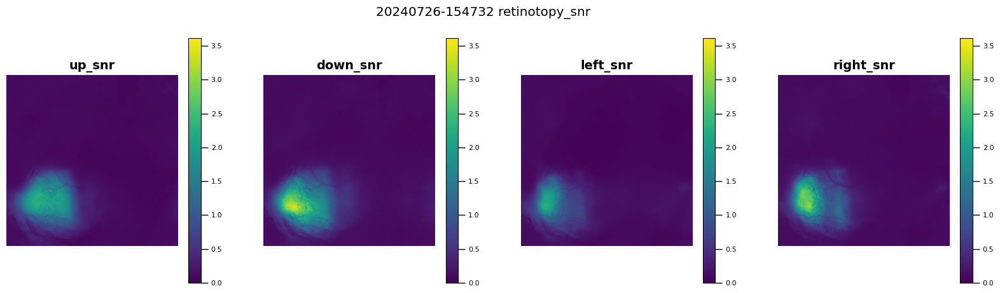

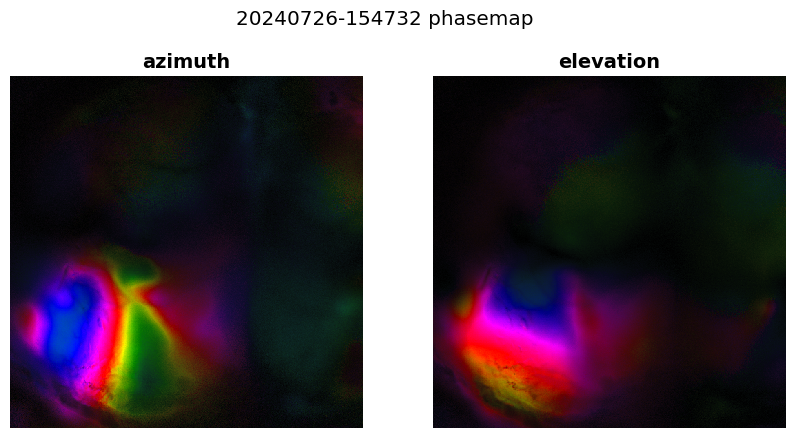

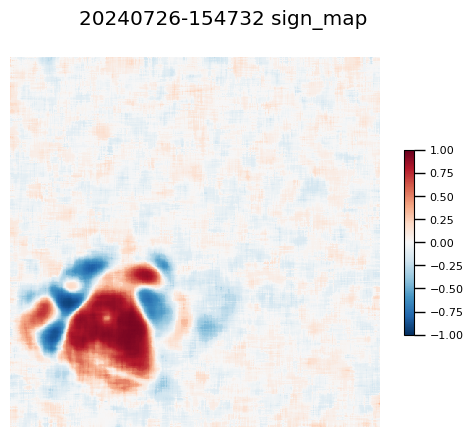

In [7]:
phasemap_tif(path_wfield, pjoin(path_wfield, 'test-tif'), tifcorr3, nrepeats=10, post_trial=3, export_ave_tif=False, export_raw_tif=False,
             plot_snr=True, plot_phasemasp=True, export_phase=False)
cp._default_memory_pool.free_all_blocks()

In [ ]:
cp._default_memory_pool.free_all_blocks()